# WICOS: pre-processing
Every spectrogram is pre-processed in four steps (`preprocess_clip` in `src/preprocessing.py`):

1. **Noise removal:** one noise level per clip, the median of the **far Doppler bins** that the hand never reaches.
   Every pixel not more than a **margin** above that level is set to the threshold (noise level + margin).
2. **Doppler crop:** keep only the bins between the two far-bin regions.
3. **Scaling:** threshold → 0, maximum → 1.
4. **Resize:** linear interpolation to 128 × 128 (Doppler × time).

This notebook first shows the four steps on one clip, then **derives** the constants they use:

* **Far bins** (`FAR_OFFSET = 340`): the Doppler bins used to estimate each clip's noise level, i.e. all bins at least
  340 bins from 0 Hz (bins 0–59 and 740–799). The same boundary is used as the Doppler crop.
* **Margin** (`MARGIN_DB = 10`): how far above the noise level a pixel must be to count as gesture.

Everything is derived on the **training clips only**, so no test information enters the pre-processing.
Every step only uses the clip itself and these fixed constants, so it can then be applied to every clip without leakage.
Doppler bins are written as the distance from zero Doppler, `|k| = |bin − 400|`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter, zoom

sys.path.insert(0, str(Path("../src").resolve()))
import preprocessing
from build_dataset import load_data, split

FIG_DIR = Path("../reports/figures")

spectrograms, metadata = load_data()
idx_train, idx_test, _ = split(metadata)
specs = [spectrograms[i] for i in idx_train]
meta = metadata.iloc[idx_train].reset_index(drop=True)
gestures, persons = meta.gesture.to_numpy(), meta.person.to_numpy()
GEST = sorted(np.unique(gestures))
print(f"{len(specs)} training clips of {len(spectrograms)}")

N_DOPPLER, ZD = 800, 400
dist = np.abs(np.arange(N_DOPPLER) - ZD)                      # |k| of every Doppler bin
OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]
C_GEST = dict(zip(GEST, OKABE))

def style(ax):
    ax.grid(alpha=0.25, lw=0.5)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

768 training clips of 960


## The four steps on one clip
The cell runs the steps one by one on a training clip and checks that `preprocess_clip` gives the same result.
Crop and scaling are shown together in one panel.

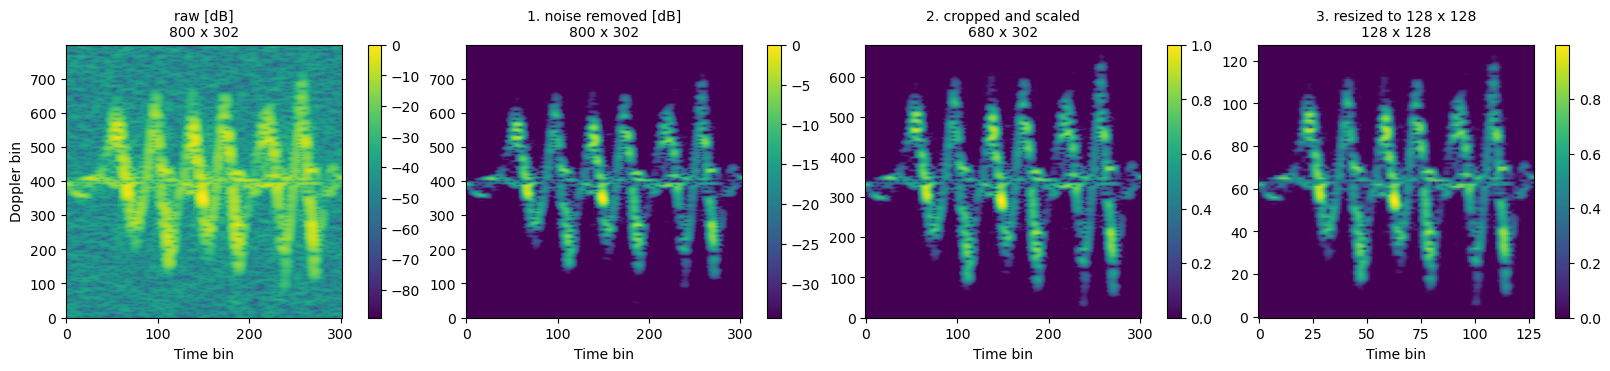

Same as preprocess_clip: True


In [2]:
x = specs[2]
x_clean, thr = preprocessing.remove_noise(x)                                     # 1. noise removal
x_crop = x_clean[preprocessing.DOPPLER_CROP[0]:preprocessing.DOPPLER_CROP[1]]    # 2. Doppler crop
x_scaled = (x_crop - thr) / (x_crop.max() - thr)                                 # 3. scaling: threshold -> 0, maximum -> 1
x_img = zoom(x_scaled, (128 / x_scaled.shape[0], 128 / x_scaled.shape[1]), order=1)  # 4. resize

steps = {"raw [dB]": x, "1. noise removed [dB]": x_clean,
         "2. cropped and scaled": x_scaled, "3. resized to 128 x 128": x_img}
fig, axes = plt.subplots(1, len(steps), figsize=(16, 3.6), constrained_layout=True)
for ax, (name, img) in zip(axes, steps.items()):
    im = ax.imshow(img, aspect="auto", origin="lower", cmap="viridis")
    ax.set_title(f"{name}\n{img.shape[0]} x {img.shape[1]}", fontsize=10)
    ax.set_xlabel("Time bin")
    fig.colorbar(im, ax=ax)
axes[0].set_ylabel("Doppler bin")
fig.savefig(FIG_DIR / "prepro_all_steps.pdf", bbox_inches="tight")
plt.show()

print("Same as preprocess_clip:", np.allclose(np.clip(x_img, 0, 1), preprocessing.preprocess_clip(x)))

## 1. Where does the gesture reach? → far bins

For each clip we need a rough noise level first. We take the median of the outer 100 bins on each side (|k| ≥ 300).
This is only provisional; section 2 shows the final level hardly depends on the exact range.
A bin is **occupied** in a clip if, after a 3×3 median filter (which removes single noise pixels), it exceeds that level by
more than 15 dB at any time. Pure noise practically never does this: its 99.9th percentile is ~10 dB above the median (section 3),
so 15 dB leaves a 5 dB safety gap.

**Broadband stripes.** Some clicks contain a short vertical stripe that lifts the *whole* Doppler band for a few frames. Such a frame is
detected by the median over all far bins in that frame: for pure noise this median of ~200 values hardly moves (over all training frames it
stays between −2.7 and +3.4 dB of the clip level, 1st to 99th percentile), so a rise of more than 4 dB can only come from energy over the
whole band (0.8% of all frames). A fast hand lifts only a
few bins and does not move this median.

For every distance K we then count the clips that have *any* occupied bin at |k| ≥ K. The far region should start where this
drops to (almost) zero.

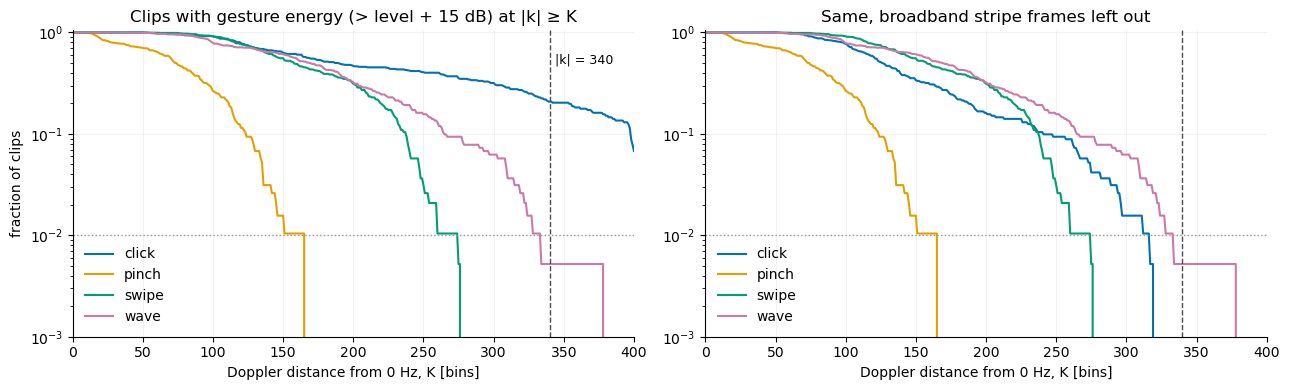

Furthest occupied |k| per gesture, stripe frames left out:
  click  median   126   P99   311   max  319   clips reaching |k| >= 340: 0
  pinch  median    73   P99   151   max  165   clips reaching |k| >= 340: 0
  swipe  median   157   P99   260   max  276   clips reaching |k| >= 340: 0
  wave   median   168   P99   328   max  378   clips reaching |k| >= 340: 1

Clips with broadband stripe frames: 122 of 768 (at most 20 frames per clip, 25% of a clip)
person   A   B   C   D   E   F
gesture                       
click    6  17  10  32  31  22
pinch    0   1   0   0   0   0
swipe    0   0   0   0   0   1
wave     1   0   0   0   1   0
Share of far-bin pixels with gesture energy per clip: median 0.00%, max 8.0% (all frames, stripes included)


In [3]:
OCC_DB = 15
STRIPE_DB = 4
lvl_prov = np.array([np.median(s[dist >= 300]) for s in specs])
far_prov = dist >= 300
exceed = [median_filter(s, 3) > l + OCC_DB for s, l in zip(specs, lvl_prov)]

# Broadband stripes: time frames in which the median over ALL far bins rises > STRIPE_DB above the level
# (+-1 frame). A hand moving fast lifts a few bins; a broadband stripe lifts the whole band at once.
stripe_frames = [np.convolve(np.median(s[far_prov], 0) - l > STRIPE_DB, np.ones(3), "same") > 0
                 for s, l in zip(specs, lvl_prov)]
stripe = np.array([sf.any() for sf in stripe_frames])

# furthest occupied distance per clip, with all frames and with stripe frames left out
def furthest(o):
    return dist[o].max() if o.any() else 0
reach_all = np.array([furthest(e.any(1)) for e in exceed])
reach = np.array([furthest(e[:, ~sf].any(1)) for e, sf in zip(exceed, stripe_frames)])
K = np.arange(0, 401)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for G in GEST:
    ax[0].plot(K, (reach_all[gestures == G][:, None] >= K).mean(0), color=C_GEST[G], lw=1.5, label=G)
ax[0].axvline(preprocessing.FAR_OFFSET, color="0.3", ls="--", lw=1)
ax[0].axhline(0.01, color="0.6", ls=":", lw=1)
ax[0].text(preprocessing.FAR_OFFSET + 4, 0.5, f"|k| = {preprocessing.FAR_OFFSET}", fontsize=9)
ax[0].set(yscale="log", ylim=(1e-3, 1.05), xlim=(0, 400), xlabel="Doppler distance from 0 Hz, K [bins]",
          ylabel="fraction of clips", title=f"Clips with gesture energy (> level + {OCC_DB} dB) at |k| ≥ K")
ax[0].legend(frameon=False)

for G in GEST:
    ax[1].plot(K, (reach[gestures == G][:, None] >= K).mean(0), color=C_GEST[G], lw=1.5, label=G)
ax[1].axvline(preprocessing.FAR_OFFSET, color="0.3", ls="--", lw=1)
ax[1].axhline(0.01, color="0.6", ls=":", lw=1)
ax[1].set(yscale="log", ylim=(1e-3, 1.05), xlim=(0, 400), xlabel="Doppler distance from 0 Hz, K [bins]",
          title="Same, broadband stripe frames left out")
ax[1].legend(frameon=False)
for a in ax: style(a)
plt.tight_layout(); plt.savefig(FIG_DIR / "noise_far_bins.pdf", bbox_inches="tight"); plt.show()

print("Furthest occupied |k| per gesture, stripe frames left out:")
for G in GEST:
    r = reach[gestures == G]
    print(f"  {G:6s} median {np.median(r):5.0f}   P99 {np.percentile(r, 99):5.0f}   max {r.max():4.0f}   "
          f"clips reaching |k| >= {preprocessing.FAR_OFFSET}: {(r >= preprocessing.FAR_OFFSET).sum()}")
n_frames = np.array([sf.sum() for sf in stripe_frames])
print(f"\nClips with broadband stripe frames: {stripe.sum()} of {len(specs)} "
      f"(at most {n_frames.max()} frames per clip, {100*np.max(n_frames / [s.shape[1] for s in specs]):.0f}% of a clip)")
print(pd.crosstab(meta.gesture[stripe], meta.person[stripe]).to_string())
far = dist >= preprocessing.FAR_OFFSET
hit = np.array([(s[far] > l + OCC_DB).mean() for s, l in zip(specs, lvl_prov)])
print(f"Share of far-bin pixels with gesture energy per clip: median {100*np.median(hit):.2f}%, "
      f"max {100*hit.max():.1f}% (all frames, stripes included)")

**Reading the plot.** Left: clicks never drop to zero. In many clicks (most clearly persons D and E) the click instant shows up as
a broadband vertical stripe that lifts the whole Doppler band for a few frames. Right: with those stripe frames left out, every
gesture has a clear maximum extent. Pinch stops at |k| ≈ 165, swipe at ≈ 275, click at ≈ 320, and wave reaches ≈ 330 in 99% of clips
(one single wave clip goes to 378). **|k| = 340** is the first round value past the point where every gesture is below 1% of
clips. So the far bins are **bins 0–59 and 740–799** (120 bins).

The stripes cannot be avoided by any choice of far bins, but they are short: they cover at most 25% of a clip's frames and at most 8%
of its far-bin pixels exceed level + 15 dB. That is why the level is the **median** of the far bins: a median is unaffected as long as
less than half the pixels are contaminated.

## 2. Is the result sensitive to the exact far range, and is the noise flat there?

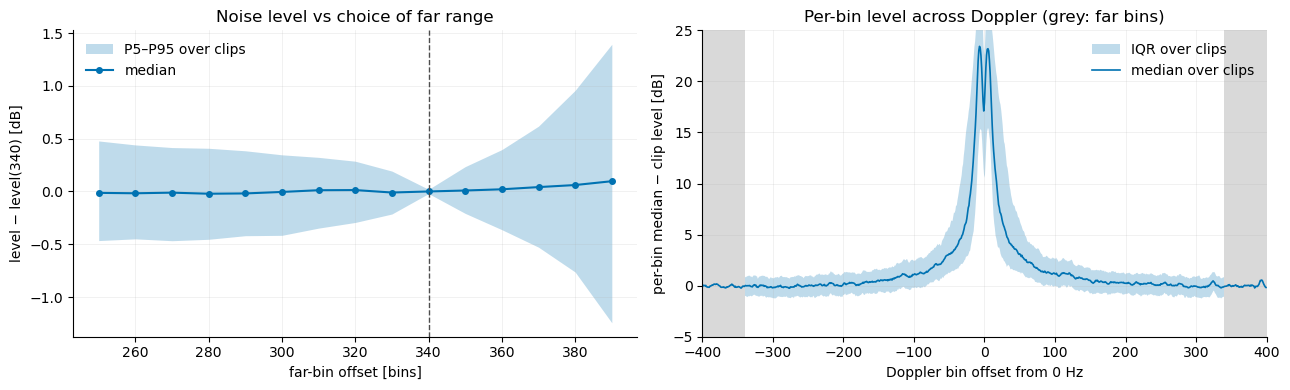

 offset  median    P5  P95
    250   -0.01 -0.47 0.48
    260   -0.02 -0.45 0.44
    270   -0.01 -0.47 0.42
    280   -0.02 -0.45 0.41
    290   -0.02 -0.42 0.39
    300   -0.00 -0.42 0.35
    310    0.01 -0.35 0.32
    320    0.01 -0.29 0.29
    330   -0.01 -0.21 0.19
    340   -0.00 -0.02 0.02
    350    0.01 -0.21 0.24
    360    0.02 -0.36 0.40
    370    0.04 -0.53 0.62
    380    0.06 -0.76 0.96
    390    0.10 -1.24 1.39

negative − positive far side: median -0.05 dB, P5..P95 -1.29 .. +0.95 dB


In [4]:
offsets = np.arange(250, 391, 10)
lvl_ref = np.array([preprocessing.noise_level(s) for s in specs])     # level with FAR_OFFSET = 340
rows = []
for off in offsets:
    l = np.array([np.median(s[dist >= off]) for s in specs])
    d = l - lvl_ref
    rows.append((off, np.median(d), np.percentile(d, 5), np.percentile(d, 95)))
sens = pd.DataFrame(rows, columns=["offset", "median", "P5", "P95"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].fill_between(sens.offset, sens.P5, sens.P95, color="#0072B2", alpha=0.25, lw=0, label="P5–P95 over clips")
ax[0].plot(sens.offset, sens["median"], color="#0072B2", lw=1.5, marker="o", ms=4, label="median")
ax[0].axvline(preprocessing.FAR_OFFSET, color="0.3", ls="--", lw=1)
ax[0].set(xlabel="far-bin offset [bins]", ylabel="level − level(340) [dB]", title="Noise level vs choice of far range")
ax[0].legend(frameon=False)

# noise profile over Doppler: per-bin median over time, relative to the clip level
prof = np.array([np.median(s, 1) - l for s, l in zip(specs, lvl_ref)])
k_axis = np.arange(N_DOPPLER) - ZD
q25, q50, q75 = np.percentile(prof, [25, 50, 75], axis=0)
ax[1].fill_between(k_axis, q25, q75, color="#0072B2", alpha=0.25, lw=0, label="IQR over clips")
ax[1].plot(k_axis, q50, color="#0072B2", lw=1.2, label="median over clips")
for sgn in (-1, 1):
    ax[1].axvspan(sgn * preprocessing.FAR_OFFSET, sgn * ZD, color="0.85", lw=0)
ax[1].set(xlim=(-ZD, ZD), ylim=(-5, 25), xlabel="Doppler bin offset from 0 Hz",
          ylabel="per-bin median − clip level [dB]", title="Per-bin level across Doppler (grey: far bins)")
ax[1].legend(frameon=False)
for a in ax: style(a)
plt.tight_layout(); plt.show()

print(sens.round(2).to_string(index=False))
lo_hi = np.array([np.median(s[:ZD - preprocessing.FAR_OFFSET]) - np.median(s[ZD + preprocessing.FAR_OFFSET:]) for s in specs])
print(f"\nnegative − positive far side: median {np.median(lo_hi):+.2f} dB, P5..P95 "
      f"{np.percentile(lo_hi, 5):+.2f} .. {np.percentile(lo_hi, 95):+.2f} dB")

Moving the far boundary anywhere between 250 and 360 bins changes the level by less than ±0.5 dB in 90% of the clips (median
change ≈ 0), so the exact value 340 is not critical. Beyond ~370 the estimate gets noisier only because fewer bins are left.
The two sides give the same level (median difference −0.05 dB). In the far region the per-bin level is flat (no roll-off at the
band edges), so one flat level per clip describes the noise there. Towards 0 Hz the level rises because of the gesture
and the residual 0-Hz line, which is exactly why the level is not estimated there.

## 3. How much does pure noise fluctuate? → margin

In the far bins (pure noise), we look at every pixel relative to the clip's noise level (median). The grey curve is the theory for
complex Gaussian noise: the power is exponentially distributed (Rayleigh amplitude), shown in dB.
The margin must be high enough that noise pixels rarely survive. The fraction that survives a margin *m* is the
"speckle" left in the image. The broadband stripe frames from section 1 are left out here, because they contain gesture energy, not noise.

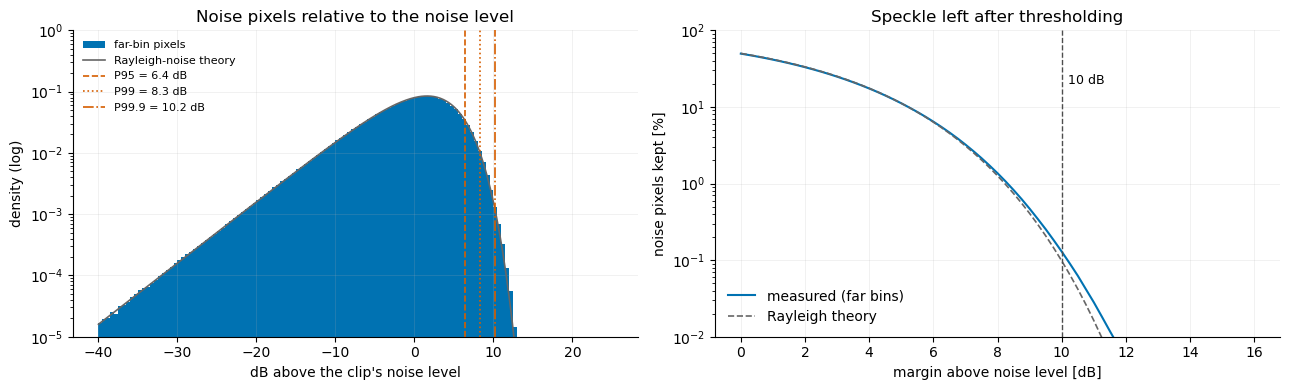

noise above the median: P95 6.4, P99 8.3, P99.9 10.2 dB (theory 6.4, 8.2, 10.0 dB)
margin  8 dB:  1.362% of noise pixels kept (theory 1.261%)
margin  9 dB:  0.468% of noise pixels kept (theory 0.406%)
margin 10 dB:  0.129% of noise pixels kept (theory 0.098%)
margin 11 dB:  0.028% of noise pixels kept (theory 0.016%)
margin 12 dB:  0.005% of noise pixels kept (theory 0.002%)


with the stripe frames included: P99 8.7, P99.9 13.4 dB, margin 10 dB keeps 0.40% of the far-bin pixels


In [5]:
rel = np.concatenate([(s[far][:, ~sf] - l).ravel() for s, l, sf in zip(specs, lvl_ref, stripe_frames)])
pcts = np.percentile(rel, [95, 99, 99.9])

def theory_exceed(m):           # P(noise > median + m dB) for exponential power with median 1
    return np.exp(-np.log(2) * 10 ** (m / 10))

margins = np.arange(0, 16.01, 0.25)
speckle = np.array([(rel > m).mean() for m in margins])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = np.linspace(-40, 25, 500); p = 10 ** (x / 10); lam = np.log(2)
ax[0].hist(rel, bins=np.linspace(-40, 25, 131), density=True, color="#0072B2", log=True, label="far-bin pixels")
ax[0].plot(x, lam * np.exp(-lam * p) * p * np.log(10) / 10, color="0.4", lw=1.2, label="Rayleigh-noise theory")
for v, lab, ls in zip(pcts, ["P95", "P99", "P99.9"], ["--", ":", "-."]):
    ax[0].axvline(v, color="#D55E00", ls=ls, lw=1.2, label=f"{lab} = {v:.1f} dB")
ax[0].set(ylim=(1e-5, 1), xlabel="dB above the clip's noise level", ylabel="density (log)",
          title="Noise pixels relative to the noise level")
ax[0].legend(frameon=False, fontsize=8)

ax[1].plot(margins, 100 * speckle, color="#0072B2", lw=1.5, label="measured (far bins)")
ax[1].plot(margins, 100 * theory_exceed(margins), color="0.4", lw=1.2, ls="--", label="Rayleigh theory")
ax[1].axvline(preprocessing.MARGIN_DB, color="0.3", ls="--", lw=1)
ax[1].text(preprocessing.MARGIN_DB + 0.2, 20, f"{preprocessing.MARGIN_DB:.0f} dB", fontsize=9)
ax[1].set(yscale="log", ylim=(1e-2, 100), xlabel="margin above noise level [dB]",
          ylabel="noise pixels kept [%]", title="Speckle left after thresholding")
ax[1].legend(frameon=False)
for a in ax: style(a)
plt.tight_layout(); plt.savefig(FIG_DIR / "noise_margin.pdf", bbox_inches="tight"); plt.show()

print(f"noise above the median: P95 {pcts[0]:.1f}, P99 {pcts[1]:.1f}, P99.9 {pcts[2]:.1f} dB "
      f"(theory {10*np.log10(np.log(20)/np.log(2)):.1f}, {10*np.log10(np.log(100)/np.log(2)):.1f}, "
      f"{10*np.log10(np.log(1000)/np.log(2)):.1f} dB)")
for m in [8, 9, 10, 11, 12]:
    print(f"margin {m:2d} dB: {100*(rel > m).mean():6.3f}% of noise pixels kept (theory {100*theory_exceed(m):.3f}%)")

rel_all = np.concatenate([(s[far] - l).ravel() for s, l in zip(specs, lvl_ref)])
print(f"with the stripe frames included: P99 {np.percentile(rel_all, 99):.1f}, P99.9 {np.percentile(rel_all, 99.9):.1f} dB, "
      f"margin {preprocessing.MARGIN_DB:.0f} dB keeps {100*(rel_all > preprocessing.MARGIN_DB).mean():.2f}% of the far-bin pixels")

The measured noise follows the Rayleigh theory closely (P95 6.4, P99 8.3, P99.9 10.2 dB vs theory 6.4, 8.2, 10.0 dB), so the
speckle is ordinary thermal noise after the STFT and its percentiles can be trusted.
A margin at the 99th percentile (≈ 8.3 dB) still leaves 1% of all noise pixels: with ~100k pixels per clip that is ~1000
isolated specks. A margin of **10 dB** sits at the 99.9th percentile and leaves 0.13% (~150 pixels per clip). Each further dB
removes much less speckle in absolute terms, but costs 1 dB of signal in every clip, which matters most for the weakest clips (section 4).

So the noise removal per clip is

$$\text{threshold} = \operatorname{median}(x_\text{far bins}) + 10\ \text{dB},$$

and every pixel at or below the threshold is set to the threshold. The noise level follows each recording, the margin is the
same for all clips. If the short broadband click stripes are counted as noise too, 0.4% of the far-bin pixels stay above the
threshold instead of 0.13%: these are gesture energy, not speckle.

In [6]:
# Noise removal on every training clip
cleaned = [preprocessing.remove_noise(s) for s in specs]        # (x_clean, threshold) per clip
thresholds = np.array([t for _, t in cleaned])
removed = np.array([(s <= t).mean() for s, t in zip(specs, thresholds)])
print(f"threshold {thresholds.min():.1f} to {thresholds.max():.1f} dB; pixels set to the threshold per clip "
      f"{removed.min():.1%} to {removed.max():.1%} (mean {removed.mean():.1%})")

threshold -49.4 to -6.9 dB; pixels set to the threshold per clip 59.0% to 99.4% (mean 89.7%)


## 4. What does the margin cost? SNR of the weakest clips
SNR = 0 dB peak − noise level. After thresholding, a clip keeps only the dynamic range between the threshold and its peak:
SNR − margin.

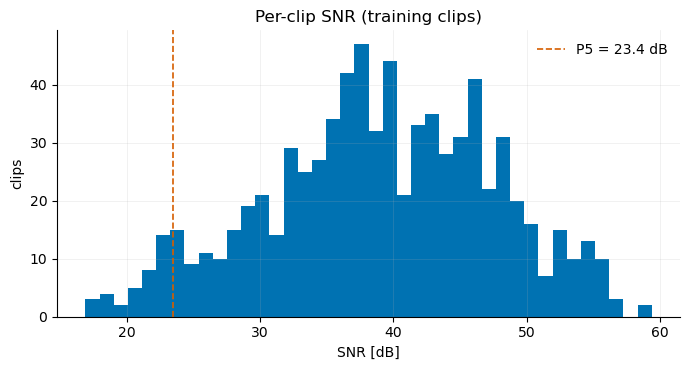

SNR: min 16.9, P5 23.4, median 39.2, max 59.4 dB
median SNR per person: {'A': 34.4, 'B': 26.8, 'C': 40.6, 'D': 47.3, 'E': 42.1, 'F': 42.7}
margin  8 dB: weakest clip keeps  8.9 dB, P5 clip keeps 15.4 dB of dynamic range
margin  9 dB: weakest clip keeps  7.9 dB, P5 clip keeps 14.4 dB of dynamic range
margin 10 dB: weakest clip keeps  6.9 dB, P5 clip keeps 13.4 dB of dynamic range
margin 11 dB: weakest clip keeps  5.9 dB, P5 clip keeps 12.4 dB of dynamic range
margin 12 dB: weakest clip keeps  4.9 dB, P5 clip keeps 11.4 dB of dynamic range


In [7]:
snr = -lvl_ref
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(snr, bins=40, color="#0072B2")
ax.axvline(np.percentile(snr, 5), color="#D55E00", ls="--", lw=1.2, label=f"P5 = {np.percentile(snr, 5):.1f} dB")
ax.legend(frameon=False)
ax.set(xlabel="SNR [dB]", ylabel="clips", title="Per-clip SNR (training clips)")
style(ax); plt.tight_layout(); plt.show()

print(f"SNR: min {snr.min():.1f}, P5 {np.percentile(snr, 5):.1f}, median {np.median(snr):.1f}, max {snr.max():.1f} dB")
print("median SNR per person:", pd.Series(snr).groupby(persons).median().round(1).to_dict())
for m in [8, 9, 10, 11, 12]:
    print(f"margin {m:2d} dB: weakest clip keeps {snr.min() - m:4.1f} dB, P5 clip keeps {np.percentile(snr, 5) - m:4.1f} dB of dynamic range")

Even the weakest training clip keeps a few dB above a 10 dB margin, and the 5% weakest keep ≥ 13 dB. So 10 dB removes
almost all speckle without wiping out the low-SNR clips (mostly person B).

## 5. Why the far-bin median and not the median of the whole clip?
The whole-clip median also contains gesture pixels, so it depends on how much of the Doppler band the gesture fills.

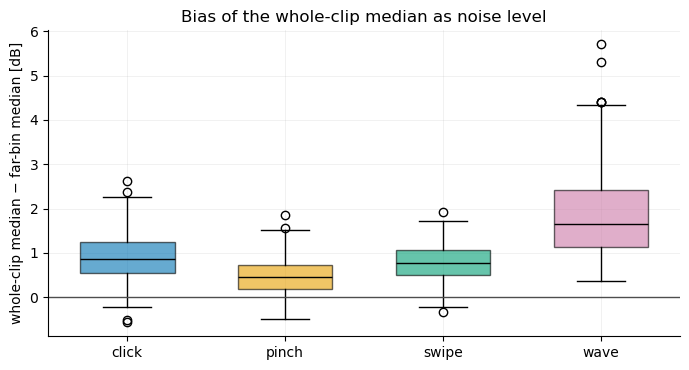

        50%   max
click  0.86  2.63
pinch  0.46  1.85
swipe  0.76  1.92
wave   1.64  5.71


In [8]:
bias = np.array([np.median(s) for s in specs]) - lvl_ref
fig, ax = plt.subplots(figsize=(7, 3.8))
bp = ax.boxplot([bias[gestures == G] for G in GEST], tick_labels=GEST, patch_artist=True, widths=0.6,
                medianprops=dict(color="black"))
for patch, G in zip(bp["boxes"], GEST):
    patch.set_facecolor(C_GEST[G]); patch.set_alpha(0.6)
ax.axhline(0, color="0.3", lw=1)
ax.set(ylabel="whole-clip median − far-bin median [dB]", title="Bias of the whole-clip median as noise level")
style(ax); plt.tight_layout(); plt.show()
print(pd.Series(bias).groupby(gestures).describe()[["50%", "max"]].round(2))

The whole-clip median lies above the noise by about 0.5 dB for pinch up to about 1.7 dB for wave, and by up to several dB in
single clips. The threshold would then depend on the gesture class. The far-bin median does not have this bias.

## 6. Doppler crop: cross-check with the gesture energy
The crop is the complement of the far bins: everything outside it is noise only (section 1). As an independent check we ask the
opposite question: how wide must a symmetric window `[400 − w, 400 + w)` be to keep the gesture energy?

* **Gesture energy per Doppler bin:** after noise removal, the linear power above the threshold, $10^{x/10} - 10^{\text{thr}/10}$,
  summed over time. Removed noise gives exactly 0, so only the gesture counts.
* **Half-width $w$ per clip:** the smallest $w$ whose window keeps at least 99% of that clip's gesture energy.

The first plot shows the retained share against $w$ for one clip per gesture (the clip with the median SNR of that gesture),
the second the smallest $w$ over all training clips.

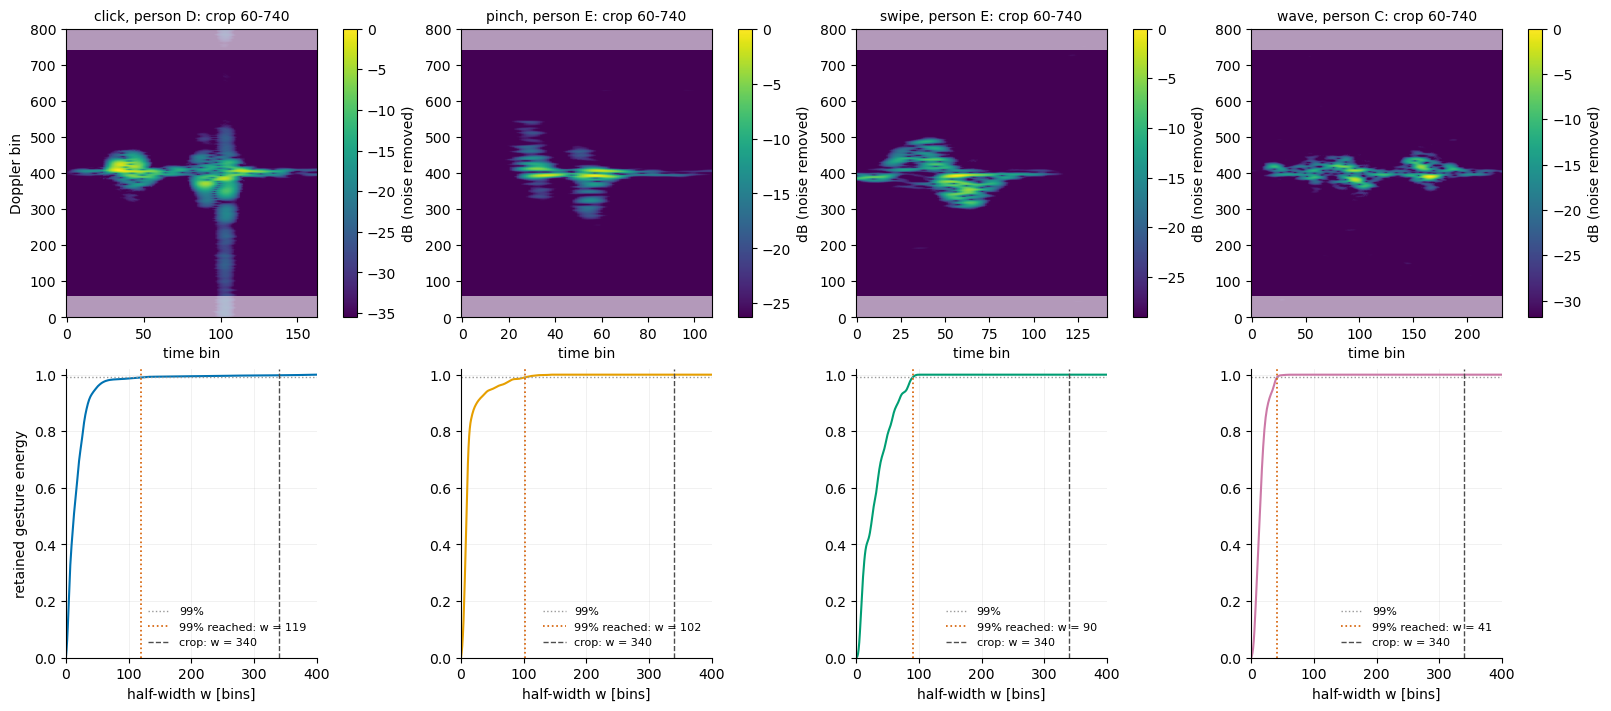

In [9]:
ENERGY_KEPT = 0.99
half_widths = np.arange(ZD + 1)
W_CROP = preprocessing.FAR_OFFSET                       # half-width of the crop

def retained_energy(x_clean, thr):
    # share of the clip's gesture energy inside [400 - w, 400 + w), for every half-width w
    energy = (10 ** (x_clean / 10) - 10 ** (thr / 10)).sum(axis=1)      # gesture energy per Doppler bin
    cum = np.r_[0, np.cumsum(energy / energy.sum())]
    return cum[ZD + half_widths] - cum[ZD - half_widths]

retained = np.stack([retained_energy(xc, t) for xc, t in cleaned])      # clips x w
w_kept = np.argmax(retained >= ENERGY_KEPT, axis=1)                    # smallest w that keeps ENERGY_KEPT

# one example clip per gesture: the clip with the median SNR of that gesture
examples = []
for G in GEST:
    ii = np.flatnonzero(gestures == G)
    examples.append(ii[np.argsort(snr[ii])[len(ii) // 2]])

fig, axes = plt.subplots(2, len(examples), figsize=(4 * len(examples), 7), constrained_layout=True)
for col, i in zip(axes.T, examples):
    x_clean = cleaned[i][0]
    im = col[0].imshow(x_clean, aspect="auto", origin="lower", cmap="viridis")
    col[0].axhspan(0, preprocessing.DOPPLER_CROP[0], color="white", alpha=0.6, lw=0)
    col[0].axhspan(preprocessing.DOPPLER_CROP[1], N_DOPPLER, color="white", alpha=0.6, lw=0)
    col[0].set_title(f"{gestures[i]}, person {persons[i]}: crop {preprocessing.DOPPLER_CROP[0]}-{preprocessing.DOPPLER_CROP[1]}",
                     fontsize=10)
    col[0].set(xlabel="time bin", ylim=(0, N_DOPPLER))
    fig.colorbar(im, ax=col[0], label="dB (noise removed)")

    col[1].plot(half_widths, retained[i], color=C_GEST[gestures[i]], lw=1.5)
    col[1].axhline(ENERGY_KEPT, color="0.6", ls=":", lw=1, label=f"{ENERGY_KEPT:.0%}")
    col[1].axvline(w_kept[i], color="#D55E00", ls=":", lw=1.2, label=f"{ENERGY_KEPT:.0%} reached: w = {w_kept[i]}")
    col[1].axvline(W_CROP, color="0.3", ls="--", lw=1, label=f"crop: w = {W_CROP}")
    col[1].set(ylim=(0, 1.02), xlim=(0, ZD), xlabel="half-width w [bins]")
    col[1].legend(frameon=False, fontsize=8, loc="lower right")
    style(col[1])
axes[0, 0].set_ylabel("Doppler bin")
axes[1, 0].set_ylabel("retained gesture energy")
fig.savefig(FIG_DIR / "prepro_crop.pdf", bbox_inches="tight")
plt.show()

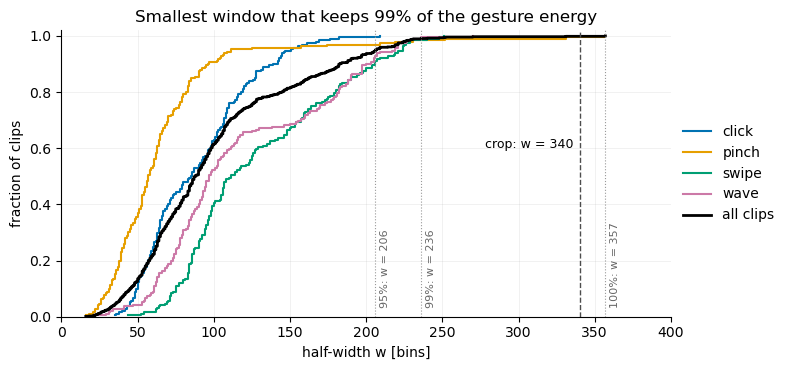

w that covers 95% of the training clips: 206
w that covers 99% of the training clips: 236
w that covers 100% of the training clips: 357
clips that need w > 340: 1 of 768
energy kept by the crop (w = 340): median 100.00%, min 98.48%
click    177.0
pinch    259.0
swipe    241.0
wave     231.0


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for G in GEST:
    w = np.sort(w_kept[gestures == G])
    ax.step(w, np.arange(1, len(w) + 1) / len(w), where="post", color=C_GEST[G], lw=1.5, label=G)
w = np.sort(w_kept)
ax.step(w, np.arange(1, len(w) + 1) / len(w), where="post", color="black", lw=2, label="all clips")
for q in [0.95, 0.99, 1.0]:                             # w needed to cover 95%, 99% and 100% of the clips
    w_q = np.quantile(w_kept, q, method="higher")
    ax.axvline(w_q, color="0.6", ls=":", lw=0.8)
    ax.text(w_q + 3, 0.03, f"{q:.0%}: w = {w_q}", rotation=90, va="bottom", fontsize=8, color="0.4")
ax.axvline(W_CROP, color="0.3", ls="--", lw=1)
ax.text(W_CROP - 4, 0.6, f"crop: w = {W_CROP}", fontsize=9, ha="right")
ax.set(xlim=(0, ZD), ylim=(0, 1.02), xlabel="half-width w [bins]", ylabel="fraction of clips",
       title=f"Smallest window that keeps {ENERGY_KEPT:.0%} of the gesture energy")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
style(ax); plt.tight_layout(); plt.savefig(FIG_DIR / "crop_energy.pdf", bbox_inches="tight"); plt.show()

for q in [0.95, 0.99, 1.0]:
    print(f"w that covers {q:.0%} of the training clips: {np.quantile(w_kept, q, method='higher')}")
print(f"clips that need w > {W_CROP}: {(w_kept > W_CROP).sum()} of {len(w_kept)}")
print(f"energy kept by the crop (w = {W_CROP}): median {np.median(retained[:, W_CROP]):.2%}, "
      f"min {retained[:, W_CROP].min():.2%}")
print(pd.Series(w_kept).groupby(gestures).quantile(0.99).round(0).to_string())

**Result.** 99% of the training clips keep 99% of their gesture energy within w = 236, and all but one within w = 340 (the
maximum is 357). So the crop at 340 is **conservative**: it never cuts a meaningful part of a gesture.

A narrower crop of about 240 would also keep 99% of the energy in 99% of the clips, and give 1.4× finer Doppler resolution after
resizing. But it would cut the faint outer parts of fast waves and clicks, which reach up to |k| ≈ 330 (section 1). Note that the
last 1% of the energy also contains the remaining noise speckle (0.13% of the noise pixels, spread over all bins): that is why
even a pinch, which never goes beyond |k| ≈ 165 (section 1), needs w ≈ 260 in its worst 1% of clips. The crop is therefore kept at
the far-bin boundary: it only removes bins that contain noise by construction.

## 7. Alternative considered: a noise floor per Doppler bin
Instead of one flat level per clip, the noise could be estimated **per Doppler bin**, as in spectral subtraction:
1. per Doppler bin, the median over time of the linear power (a gesture is short, so most time bins only hold noise);
2. subtract it from the linear power and clip negative values to 0;
3. back to dB, keep a 40 dB dynamic range below the maximum;
4. a 3 × 3 median filter to remove remaining isolated noise pixels.

The cell below compares it with the chosen method on a low-SNR training clip (5th percentile of the SNR).

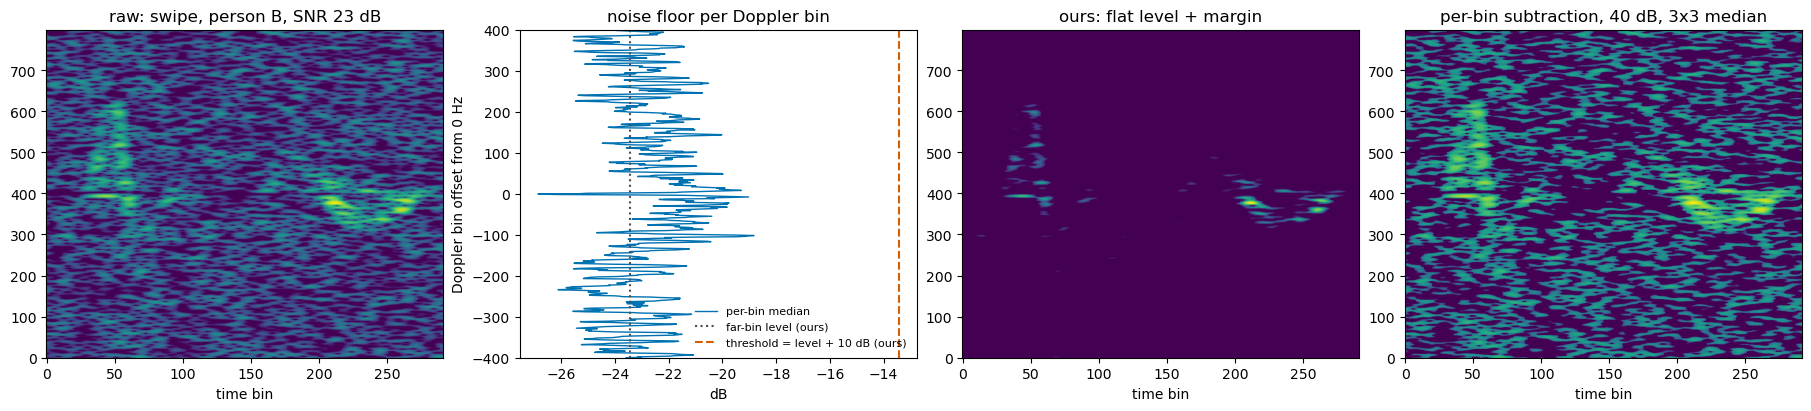

pixels kept as gesture: ours 2.5%, per-bin subtraction 49.4%


In [11]:
from scipy.signal import medfilt2d

DYNAMIC_RANGE = 40                                      # dB kept below the clip maximum
i_alt = np.argsort(snr)[int(0.05 * len(snr))]           # a low-SNR clip (5th percentile)
s = specs[i_alt]

S = 10 ** (s / 10)                                      # linear power
floor_per_bin = np.median(S, axis=1, keepdims=True)     # 1. per-Doppler noise floor
S_sub = np.clip(S - floor_per_bin, 0, None)             # 2. spectral subtraction
S_db = 10 * np.log10(S_sub + 1e-12)
S_db = np.maximum(S_db, S_db.max() - DYNAMIC_RANGE)     # 3. dynamic range
S_filt = medfilt2d(S_db, kernel_size=3)                 # 4. speckle removal
x_ours, thr = preprocessing.remove_noise(s)

fig, ax = plt.subplots(1, 4, figsize=(18, 4), layout="constrained")
ax[0].imshow(s, aspect="auto", origin="lower", cmap="viridis", vmin=preprocessing.noise_level(s) - 5, vmax=0)
ax[0].set_title(f"raw: {gestures[i_alt]}, person {persons[i_alt]}, SNR {snr[i_alt]:.0f} dB")
ax[1].plot(10 * np.log10(floor_per_bin.ravel()), np.arange(N_DOPPLER) - ZD, color="#0072B2", lw=1, label="per-bin median")
ax[1].axvline(preprocessing.noise_level(s), color="0.3", ls=":", label="far-bin level (ours)")
ax[1].axvline(thr, color="#D55E00", ls="--", label="threshold = level + 10 dB (ours)")
ax[1].set(ylim=(-ZD, ZD), xlabel="dB", ylabel="Doppler bin offset from 0 Hz", title="noise floor per Doppler bin")
ax[1].legend(frameon=False, fontsize=8)
ax[2].imshow(x_ours, aspect="auto", origin="lower", cmap="viridis")
ax[2].set_title("ours: flat level + margin")
ax[3].imshow(S_filt, aspect="auto", origin="lower", cmap="viridis")
ax[3].set_title(f"per-bin subtraction, {DYNAMIC_RANGE} dB, 3x3 median")
for a in ax[[0, 2, 3]]:
    a.set_xlabel("time bin")
plt.show()

print(f"pixels kept as gesture: ours {(s > thr).mean():.1%}, "
      f"per-bin subtraction {(S_filt > S_filt.max() - DYNAMIC_RANGE).mean():.1%}")

**Why not chosen.**
* Subtracting the per-bin **median** leaves about half of the noise pixels positive (the median is the middle of the noise,
  section 3): 49% of the pixels survive as "gesture", against 2.5% with our threshold. It would need a margin as well, on top of
  the dynamic range and the median filter: more parameters for the same job.
* Near 0 Hz a long gesture (wave) is present in many time bins, so the per-bin median there partly *is* gesture and is
  subtracted from it.
* In the far bins the noise is flat across Doppler (section 2), so one level per clip describes it. The only Doppler-dependent
  part is the residual 0 Hz line, which a per-bin floor would remove better; it is the one advantage of this alternative.

## 8. Scaling and resizing
* **Scaling:** $(x - \text{thr}) / (\max x - \text{thr})$, so the threshold becomes 0 and the clip maximum 1. Every clip is peak-normalised
  to 0 dB, so the denominator is the clip's own dynamic range above the threshold, SNR − margin (section 4). This removes the
  gain differences between recordings (person B is ~15 dB noisier, see `1_data_exploration.ipynb`). The values stay on a dB
  scale, so weak parts of the gesture remain visible next to the strongest pixel.
* **Resize to 128 × 128:** linear interpolation.
  * *Doppler:* the 680 cropped bins are scaled by the **same** factor (680/128 ≈ 5.3) for every clip, so a row keeps the same
    velocity meaning in every image. The cost is resolution: a pinch, which stays within |k| < 165, covers only about
    2 · 165 / 5.3 ≈ 62 of the 128 rows.
  * *Time:* the clips have 43 to 448 time bins, so every clip is stretched to 128 columns. This removes the duration
    from the images; the envelope features keep it as the gesture length T (`3_features.ipynb`).
  * 128 is close to the median clip length, keeps the flattened image small enough for PCA (16 384 values), and divides
    by 2 repeatedly for the pooling layers of the CNN. It was not tuned.

The cell below pre-processes every clip (training and test) with these fixed constants.

In [12]:
X_img = preprocessing.preprocess(spectrograms)
print(f"X_img: {X_img.shape}, values from {X_img.min():.2f} to {X_img.max():.2f}")

X_img: (960, 128, 128), values from 0.00 to 1.00


## Summary for the report

| parameter | value | how it was chosen |
|---|---|---|
| far bins | \|k\| ≥ 340 (bins 0–59, 740–799) | first round distance where every gesture occupies < 1% of training clips (wave P99 ≈ 330, click ≈ 320 without stripe frames); level changes < ±0.5 dB for any offset 250–360 |
| noise level | median of the far-bin pixels, per clip | robust to the short broadband click stripes (≤ 8% of far pixels); unbiased, unlike the whole-clip median (+0.5 to +1.6 dB, gesture-dependent) |
| margin | 10 dB | 99.9th percentile of the far-bin noise (10.2 dB measured, 10.0 dB theory), leaves 0.13% speckle; the 5% weakest clips still keep ≥ 13 dB of dynamic range |
| Doppler crop | bins 60–739 | the complement of the far bins: everything outside is noise only; cross-check: 99% of the training clips keep 99% of their gesture energy within w = 236, all but one within 340 (section 6) |
| scaling | threshold → 0, max → 1 | removes gain differences between recordings; per clip, no learned constant |
| resize | 128 × 128 | fixed Doppler factor (rows keep their velocity meaning); time stretched per clip (duration kept in the features) |

## Example: raw vs pre-processed
One training clip per gesture (the clip with the median SNR of that gesture). Top: raw spectrogram in dB (colour range from
5 dB below the noise level to the 0 dB peak), with the far bins shaded and the crop boundaries dashed. Bottom: the output of
`preprocessing.preprocess_clip` (noise removed, cropped to bins 60–739, scaled to [0, 1], resized to 128 × 128).

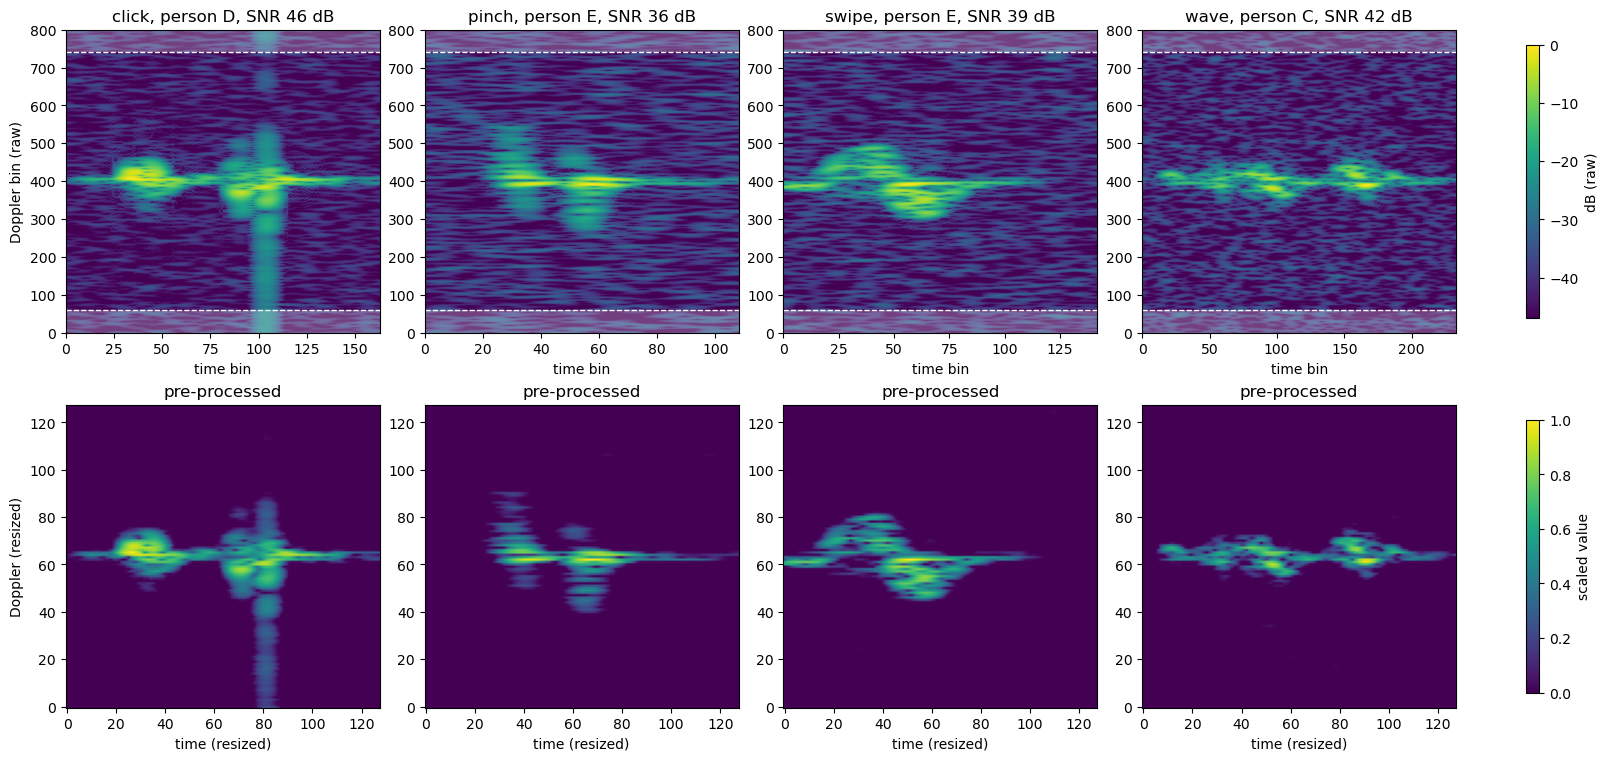

In [13]:
# examples: the median-SNR clip per gesture, chosen in section 6
fig, ax = plt.subplots(2, len(examples), figsize=(4 * len(examples), 7.5), layout="constrained")
for c, i in enumerate(examples):
    s = specs[i]
    a = ax[0, c]
    im0 = a.imshow(s, aspect="auto", origin="lower", cmap="viridis", vmin=preprocessing.noise_level(s) - 5, vmax=0,
                   extent=[0, s.shape[1], 0, N_DOPPLER])
    for lo, hi in [(0, ZD - preprocessing.FAR_OFFSET), (ZD + preprocessing.FAR_OFFSET, N_DOPPLER)]:
        a.axhspan(lo, hi, color="white", alpha=0.25, lw=0)
    for b in preprocessing.DOPPLER_CROP:
        a.axhline(b, color="white", ls="--", lw=1)
    a.set(title=f"{gestures[i]}, person {persons[i]}, SNR {snr[i]:.0f} dB", xlabel="time bin")
    a = ax[1, c]
    im1 = a.imshow(preprocessing.preprocess_clip(s), aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
    a.set(title="pre-processed", xlabel="time (resized)")
ax[0, 0].set_ylabel("Doppler bin (raw)")
ax[1, 0].set_ylabel("Doppler (resized)")
fig.colorbar(im0, ax=ax[0], label="dB (raw)", shrink=0.9)
fig.colorbar(im1, ax=ax[1], label="scaled value", shrink=0.9)
plt.savefig(FIG_DIR / "prepro_examples.pdf", bbox_inches="tight"); plt.show()